# Prueba Phyton: Cadena Hotelera

## 🎯 Enfoque análitico

El análisis se centra en los canales de venta y los distintos tipos de cliente. El trabajo se ha realizado principalmente con las tablas `Canals`, `Clients` y `Reserves`; `Habitacions` y `Hotels` se usan solo como apoyo (validación de precios y enlace de datos).

**Preguntas de negocio a desarrollar**:

- **Rentabilidad**: ¿qué canal trae a qué cliente y cuánto valor real deja al hotel? El valor se mide como ingreso neto (tras comisión), tarifa media neta por noche y porcentaje de reservas no completadas.

- **Estabilidad: Negocio vs Ocio**: ¿qué perfil de cliente genera una demanda más regular a lo largo del año y qué oportunidad representa? Se mide con las noches completadas por mes y su variación mensual.

**Notas**:
- Solo las reservas catalogadas como `Completada` generan noches e ingresos, y las reservas sin cliente identificado (~14 %) se analizan como un grupo propio, `No identificat`.
- El análisis se resume en 5 visualizaciones y termina con dos propuestas respaldadas por los datos y con sus limitaciones.

## 📂 Carga de datos y comprobaciones

### 🗂️ Carga de archivos .csv

In [63]:
## Configuració visual (paleta de marca)
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

COLORS = {
    "series":       ["#015BD2", "#0599C3", "#6B56EC", "#3577D7", "#B285F5"],
    "tipus_canal":  {"Directe": "#015BD2", "OTA": "#6B56EC",
                     "Corporatiu": "#0599C3", "Intermediari": "#B285F5"},
    "estat":        {"Completada": "#015BD2", "Cancel·lada": "#6B56EC", "No-show": "#B285F5"},
    "tipus_client": {"Negocis": "#015BD2", "Oci": "#0599C3", "No identificat": "#667085"},
    "highlight":    {"focus": "#6B56EC", "muted": "#E2EBF8"},
    "sequential":   {"low": "#E2EBF8", "high": "#015BD2"},
    "diverging":    {"neg": "#6B56EC", "mid": "#E2EBF8", "pos": "#015BD2"},
    "text":         {"title": "#015BD2", "body": "#1F2937", "caption": "#667085"},
    "structure":    {"background": "#FFFFFF", "grid": "#E2EBF8", "divider": "#E2EBF8"},
}

plt.rcParams.update({
    "figure.facecolor": COLORS["structure"]["background"],
    "axes.facecolor": COLORS["structure"]["background"],
    "axes.edgecolor": COLORS["structure"]["divider"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": COLORS["text"]["caption"],
    "axes.titlecolor": COLORS["text"]["title"],
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 13,
    "text.color": COLORS["text"]["body"],
    "xtick.color": COLORS["text"]["caption"], "ytick.color": COLORS["text"]["body"],
    "grid.color": COLORS["structure"]["grid"], "font.size": 11,
})

os.makedirs("img", exist_ok=True)
def desa(fig, nom):                       # guarda el gráfico como PNG
    fig.savefig(f"img/{nom}.png", dpi=200, bbox_inches="tight")

def n1(v):                                # 1 decimal con coma (català)
    return f"{v:.1f}".replace(".", ",")

In [64]:
## Cargar de archivos .csv
canals = pd.read_csv("/content/canals.csv", sep=",", encoding="UTF-8")
clients = pd.read_csv("/content/clients.csv", sep=",", encoding="UTF-8")
habitacions = pd.read_csv("/content/habitacions.csv", sep=",", encoding="UTF-8")
hotels = pd.read_csv("/content/hotels.csv", sep=",", encoding="UTF-8")
reserves = pd.read_csv("/content/reserves.csv", sep=",", encoding="UTF-8")

### ♻️ Correcciones básicas

In [65]:
clients["tipus_client"] = clients["tipus_client"].str.strip().str.title()
clients["tipus_client"].unique()

array(['Oci', 'Negocis'], dtype=object)

In [66]:
reserves["preu_nit_eur"] = (
    reserves["preu_nit_eur"]
    .str.strip()
    .str.replace(",", ".")
    .astype(float)
)

In [67]:
columnas_fecha = ["data_reserva", "data_entrada", "data_sortida"]

for columna in columnas_fecha:
    reserves[columna] = pd.to_datetime(
        reserves[columna],
        format="mixed",
        dayfirst=True
    )

In [68]:
reserves["estat"] = (
    reserves["estat"]
    .str.strip()
    .replace({
        "completada": "Completada",
        "cancel·lada": "Cancel·lada",
        "no-show": "No-show"
    })
)
reserves["estat"].unique()

array(['Completada', 'Cancel·lada', 'No-show'], dtype=object)

In [69]:
habitacions["tipus_habitacio"] = habitacions["tipus_habitacio"].str.strip().str.title()
habitacions["tipus_habitacio"].unique()

array(['Individual', 'Doble', 'Superior', 'Suite'], dtype=object)

### ✅ Comprobaciones

In [70]:
## Validación estructural (nulos y duplicados de ID)
tablas = {
    "canals":      ("canal_id", canals),
    "clients":     ("client_id", clients),
    "habitacions": ("habitacio_id", habitacions),
    "hotels":      ("hotel_id", hotels),
    "reserves":    ("reserva_id", reserves),
}

validacio = pd.DataFrame({
    nom: {
        "files": len(df),
        "nuls_totals": df.isnull().sum().sum(),
        "columnes_amb_nuls": ", ".join(df.columns[df.isnull().any()]) or "-",
        "ids_duplicats": df[pk].duplicated().sum(),
    }
    for nom, (pk, df) in tablas.items()
}).T

validacio

,files,nuls_totals,columnes_amb_nuls,ids_duplicats
canals,6,0,-,0
clients,6500,0,-,0
habitacions,304,0,-,0
hotels,10,0,-,0
reserves,28000,3845,client_id,0


In [71]:
## Integridad
integritat_canals = reserves[~reserves["canal_id"].isin(canals["canal_id"])]
integritat_hotels = habitacions[~habitacions["hotel_id"].isin(hotels["hotel_id"])]
integritat_habitacions = reserves[~reserves["habitacio_id"].isin(habitacions["habitacio_id"])]
integritat_clients = reserves[
    reserves["client_id"].notna()
    & ~reserves["client_id"].isin(clients["client_id"])
]

display(
    integritat_canals,
    integritat_hotels,
    integritat_habitacions,
    integritat_clients)


,reserva_id,client_id,habitacio_id,canal_id,data_reserva,data_entrada,data_sortida,estat,preu_nit_eur,nombre_hostes


,habitacio_id,hotel_id,tipus_habitacio,preu_base_eur


,reserva_id,client_id,habitacio_id,canal_id,data_reserva,data_entrada,data_sortida,estat,preu_nit_eur,nombre_hostes


,reserva_id,client_id,habitacio_id,canal_id,data_reserva,data_entrada,data_sortida,estat,preu_nit_eur,nombre_hostes


In [72]:
## Datos numericos
describe_habitacions = habitacions["preu_base_eur"].describe()
describe_reserves = reserves[["preu_nit_eur", "nombre_hostes"]].describe()

display(
    describe_habitacions,
    describe_reserves)

,preu_base_eur
count,304.000000
mean,120.873158
std,50.431723
min,58.700000
25%,85.377500
50%,108.165000
75%,142.575000
max,357.410000


,preu_nit_eur,nombre_hostes
count,28000.000000,28000.000000
mean,139.871864,1.469536
std,57.660081,0.690665
min,42.000000,1.000000
25%,101.147500,1.000000
50%,126.695000,1.000000
75%,164.252500,2.000000
max,516.530000,4.000000


In [73]:
## Comprobación fechas
reserves[columnas_fecha].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28000 entries, 0 to 27999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   data_reserva  28000 non-null  datetime64[ns]
 1   data_entrada  28000 non-null  datetime64[ns]
 2   data_sortida  28000 non-null  datetime64[ns]
dtypes: datetime64[ns](3)
memory usage: 656.4 KB


In [74]:
## Duplicados por contenido (misma reserva con distinto ID)
cols_contingut = [c for c in reserves.columns if c != "reserva_id"]
reserves.duplicated(subset=cols_contingut).sum()

np.int64(0)

## 🧠 Análisis general

### ♾️ Creación y revisión de tabla maestra `master`

In [75]:
## Tabla maestra: 1 fila = 1 reserva
master = (
    reserves
    .merge(canals, on="canal_id", how="left", validate="m:1")
    .merge(clients, on="client_id", how="left", validate="m:1")
    .merge(habitacions, on="habitacio_id", how="left", validate="m:1")
    .merge(hotels, on="hotel_id", how="left", validate="m:1")
)

## Comprobacion de errores
assert len(master) == len(reserves), "El merge ha cambiado el número de filas"

## Nueva columna "registro clientes"
master["identificat"] = master["client_id"].notna()
for col in ["pais_residencia", "tipus_client", "nivell_fidelitat"]:
    master[col] = master[col].fillna("No identificat")

## Nueva columna "estancia y valor"
master["nits"] = (master["data_sortida"] - master["data_entrada"]).dt.days
master["valor_reserva"] = master["nits"] * master["preu_nit_eur"]

## Nueva columna "estados booleanos para comprobar tasa"
master["es_completada"] = master["estat"].eq("Completada")
master["es_cancelada"] = master["estat"].eq("Cancel·lada")
master["es_noshow"] = master["estat"].eq("No-show")

## Nueva columnas "categorizacion de reserva y costes"
master["nits_completades"] = master["nits"].where(master["es_completada"])
master["ingressos_bruts"] = master["valor_reserva"].where(master["es_completada"])
master["cost_comissio"] = master["ingressos_bruts"] * master["comissio_pct"] / 100
master["ingressos_nets"] = master["ingressos_bruts"] - master["cost_comissio"]

# Nueva columna "comprobaciones horarias"
master["antelacio_dies"] = (master["data_entrada"] - master["data_reserva"]).dt.days
master["mes_entrada"] = master["data_entrada"].dt.month
master["dia_setmana_entrada"] = master["data_entrada"].dt.dayofweek   # 0 = dilluns
master["ratio_preu_base"] = master["preu_nit_eur"] / master["preu_base_eur"]

print(master.shape)
master.head()

(28000, 36)


,reserva_id,client_id,habitacio_id,canal_id,data_reserva,data_entrada,data_sortida,estat,preu_nit_eur,nombre_hostes,...,es_cancelada,es_noshow,nits_completades,ingressos_bruts,cost_comissio,ingressos_nets,antelacio_dies,mes_entrada,dia_setmana_entrada,ratio_preu_base
0,B000001,C01399,R0259,CH04,2025-07-08,2025-09-09,2025-09-10,Completada,134.92,2,...,False,False,1.0,134.92,31.0316,103.8884,63,9,1,1.236097
1,B000002,C02782,R0198,CH04,2025-06-22,2025-08-31,2025-09-06,Completada,117.52,2,...,False,False,6.0,705.12,162.1776,542.9424,70,8,6,1.121588
2,B000003,C06339,R0275,CH06,2025-05-13,2025-07-01,2025-07-03,Completada,106.50,1,...,False,False,2.0,213.00,25.5600,187.4400,49,7,1,0.931759
3,B000004,NaN,R0227,CH06,2024-11-23,2025-01-30,2025-02-02,Completada,43.25,1,...,False,False,3.0,129.75,15.5700,114.1800,68,1,3,0.736797
4,B000005,C01623,R0089,CH06,2024-12-26,2025-02-10,2025-02-12,Completada,93.79,2,...,False,False,2.0,187.58,22.5096,165.0704,46,2,0,0.906359


In [76]:
## Comprobaciones de la tabla maestra
comprovacions = pd.DataFrame([
    ("Reserves amb nits <= 0", (master["nits"] <= 0).sum(), "0"),
    ("Nits màxim d'una reserva", master["nits"].max(), "Valor raonable"),
    ("data_reserva posterior a data_entrada", (master["data_reserva"] > master["data_entrada"]).sum(), "0"),
    ("Entrades fora de 2025", (master["data_entrada"].dt.year != 2025).sum(), "0"),
    ("Primera data_entrada", master["data_entrada"].min().date(), "2025-01-01 aprox."),
    ("Última data_entrada", master["data_entrada"].max().date(), "2025-12-31 aprox."),
    ("Reserves sense canal o hotel", master["nom_canal"].isna().sum() + master["ciutat"].isna().sum(), "0"),
], columns=["Comprovació", "Resultat", "Esperat"])

comprovacions

,Comprovació,Resultat,Esperat
0,Reserves amb nits <= 0,0,0
1,Nits màxim d'una reserva,24,Valor raonable
2,data_reserva posterior a data_entrada,0,0
3,Entrades fora de 2025,0,0
4,Primera data_entrada,2025-01-01,2025-01-01 aprox.
5,Última data_entrada,2025-12-30,2025-12-31 aprox.
6,Reserves sense canal o hotel,0,0


In [77]:
## Ratio precio contratado / precio base
display(master["ratio_preu_base"].describe(percentiles=[.01, .05, .5, .95, .99]).round(2))

master.nlargest(10, "ratio_preu_base")[
    ["reserva_id", "nom_canal", "tipus_habitacio", "preu_nit_eur",
     "preu_base_eur", "ratio_preu_base", "estat"]
]

,ratio_preu_base
count,28000.00
mean,1.13
std,0.20
min,0.49
1%,0.71
5%,0.82
50%,1.12
95%,1.47
99%,1.73
max,2.29


,reserva_id,nom_canal,tipus_habitacio,preu_nit_eur,preu_base_eur,ratio_preu_base,estat
17108,B017109,Web directa,Superior,350.17,153.07,2.287646,Cancel·lada
18493,B018494,Agència Pro,Superior,240.30,108.23,2.220272,Cancel·lada
18069,B018070,App directa,Superior,332.51,152.19,2.184835,Completada
9878,B009879,Web directa,Doble,180.91,84.34,2.145008,Completada
1521,B001522,Agència Pro,Suite,412.18,195.08,2.112877,Completada
1068,B001069,RoomsHub,Superior,305.20,145.08,2.103667,Cancel·lada
11595,B011596,StayNow,Doble,166.48,80.80,2.060396,Completada
8849,B008850,Empresa,Superior,222.18,108.23,2.052850,Completada
26433,B026434,StayNow,Doble,223.58,109.35,2.044627,Completada
10923,B010924,Web directa,Doble,164.10,81.71,2.008322,Completada


In [78]:
## ¿Cuántas reservas hay en cada segmento?
display(pd.crosstab(master["nom_canal"], master["tipus_client"], margins=True))
display(pd.crosstab([master["tipus_client"], master["nivell_fidelitat"]],
                    master["estat"], margins=True))

tipus_client,Negocis,No identificat,Oci,All
nom_canal,,,,
Agència Pro,825,375,1337,2537
App directa,1599,554,2307,4460
Empresa,4304,285,273,4862
RoomsHub,487,618,2021,3126
StayNow,968,1085,3609,5662
Web directa,2677,928,3748,7353
All,10860,3845,13295,28000


estat                            Cancel·lada  Completada  No-show    All
tipus_client   nivell_fidelitat                                         
Negocis        Cap                       274        2748       48   3070
               Gold                      305        3702       60   4067
               Silver                    323        3360       40   3723
No identificat No identificat            536        3254       55   3845
Oci            Cap                       968        5154       94   6216
               Gold                      428        2465       34   2927
               Silver                    620        3467       65   4152
All                                     3454       24150      396  28000

In [79]:
## % de reservas no identificadas por canal
display(master.groupby("nom_canal")["identificat"].mean().mul(100).round(1).rename("% identificat"))

,% identificat
nom_canal,
Agència Pro,85.2
App directa,87.6
Empresa,94.1
RoomsHub,80.2
StayNow,80.8
Web directa,87.4


In [80]:
## Reservas por client identificat (¿tiene sentido un análisis por cliente?)
master[master["identificat"]].groupby("client_id").size().describe().rename("reserves_per_client")

,reserves_per_client
count,5975.000000
mean,4.042678
std,3.161593
min,1.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,21.000000


### 📚 Cálculos y tablas de estudio

In [81]:
## R1 · Resumen por canal
master["es_no_completada"] = ~master["es_completada"]

resum_canal = (
    master.groupby(["nom_canal", "tipus_canal"], as_index=False)
    .agg(
        reserves=("reserva_id", "count"),
        comissio_pct=("comissio_pct", "first"),
        pct_no_completada=("es_no_completada", "mean"),
        nits=("nits_completades", "sum"),
        ingressos_bruts=("ingressos_bruts", "sum"),
        ingressos_nets=("ingressos_nets", "sum"),
    )
)

resum_canal["pct_no_completada"] *= 100
resum_canal["tar_mitjana_brut"] = resum_canal["ingressos_bruts"] / resum_canal["nits"]   # ponderado por noches
resum_canal["tar_mitjana_net"] = resum_canal["ingressos_nets"] / resum_canal["nits"]

resum_canal.round(2).sort_values("ingressos_nets", ascending=False)

,nom_canal,tipus_canal,reserves,comissio_pct,pct_no_completada,nits,ingressos_bruts,ingressos_nets,tar_mitjana_brut,tar_mitjana_net
5,Web directa,Directe,7353,0.0,10.16,18341.0,2554986.84,2554986.84,139.30,139.30
1,App directa,Directe,4460,0.0,9.13,11391.0,1580941.36,1580941.36,138.79,138.79
4,StayNow,OTA,5662,18.0,21.25,13237.0,1779845.46,1459473.28,134.46,110.26
2,Empresa,Corporatiu,4862,6.0,5.29,9838.0,1419278.10,1334121.41,144.26,135.61
0,Agència Pro,Intermediari,2537,12.0,13.84,6074.0,854360.47,751837.21,140.66,123.78
3,RoomsHub,OTA,3126,23.0,28.31,6651.0,898218.25,691628.05,135.05,103.99


In [82]:
## R1b · Ingreso neto por reserva recibida
resum_canal["ingres_net_per_reserva"] = resum_canal["ingressos_nets"] / resum_canal["reserves"]
display(resum_canal[["nom_canal", "ingres_net_per_reserva"]]
        .sort_values("ingres_net_per_reserva", ascending=False).round(1))

## Ratio precio contratado / precio base, mediana por canal (compara a igualdad de habitación)
master.groupby("nom_canal")["ratio_preu_base"].median().round(3).sort_values()

,nom_canal,ingres_net_per_reserva
1,App directa,354.5
5,Web directa,347.5
0,Agència Pro,296.3
2,Empresa,274.4
4,StayNow,257.8
3,RoomsHub,221.3


,ratio_preu_base
nom_canal,
App directa,1.092
Web directa,1.107
StayNow,1.108
RoomsHub,1.113
Agència Pro,1.119
Empresa,1.169


In [83]:
## R2 · Cascada de valor
cascada = pd.Series({
    "Valor reservat":    master["valor_reserva"].sum(),
    "Cancel·lades":     -master.loc[master["es_cancelada"], "valor_reserva"].sum(),
    "No-show":          -master.loc[master["es_noshow"], "valor_reserva"].sum(),
    "Comissions":       -master["cost_comissio"].sum(),
}).round(0)

cascada["Ingrés net"] = cascada.sum()

# Control: reservado - cancelado - no-show debe igualar el bruto de completadas
assert abs(cascada.iloc[:3].sum() - master["ingressos_bruts"].sum()) < 1

cascada

,0
Valor reservat,10667254.0
Cancel·lades,-1426489.0
No-show,-153134.0
Comissions,-714642.0
Ingrés net,8372989.0


In [84]:
## R3 · Reparto y tasa de no completadas por canal × tipo de cliente
ordre_client = ["Oci", "Negocis", "No identificat"]

n_canal_client = pd.crosstab(master["nom_canal"], master["tipus_client"])[ordre_client]

mix_canal_client = (n_canal_client.div(n_canal_client.sum(axis=1), axis=0) * 100).round(1)

fallides_canal_client = (
    master.pivot_table(index="nom_canal", columns="tipus_client",
                       values="es_no_completada", aggfunc="mean")[ordre_client] * 100
).round(1)

display(mix_canal_client)
display(fallides_canal_client)

tipus_client,Oci,Negocis,No identificat
nom_canal,,,
Agència Pro,52.7,32.5,14.8
App directa,51.7,35.9,12.4
Empresa,5.6,88.5,5.9
RoomsHub,64.7,15.6,19.8
StayNow,63.7,17.1,19.2
Web directa,51.0,36.4,12.6


tipus_client,Oci,Negocis,No identificat
nom_canal,,,
Agència Pro,13.5,13.6,15.5
App directa,10.0,8.3,8.1
Empresa,7.3,5.2,4.2
RoomsHub,29.4,24.8,27.3
StayNow,22.2,18.6,20.4
Web directa,10.2,10.5,9.3


In [85]:
## Noches completadas por mes y tipo de cliente
nits_mes = (
    master[master["tipus_client"].isin(["Oci", "Negocis"])]
    .pivot_table(index="mes_entrada", columns="tipus_client",
                 values="nits_completades", aggfunc="sum")
    .reindex(range(1, 13))
)

index_100 = nits_mes / nits_mes.mean() * 100
cv = (nits_mes.std() / nits_mes.mean() * 100).round(1)

display(nits_mes)
display(cv.rename("Variació mensual (%)"))

tipus_client,Negocis,Oci
mes_entrada,,
1,1703.0,2647.0
2,1503.0,2408.0
3,1819.0,2895.0
4,1791.0,2964.0
5,1949.0,3150.0
6,1885.0,3090.0
7,1970.0,3249.0
8,903.0,3436.0
9,1821.0,2962.0


,Variació mensual (%)
tipus_client,
Negocis,17.4
Oci,9.9


In [86]:
## Control: variación mensual sin agosto
sense_agost = nits_mes.drop(8)
(sense_agost.std() / sense_agost.mean() * 100).round(1).rename("Variació sense agost (%)")

,Variació sense agost (%)
tipus_client,
Negocis,9.0
Oci,9.0


In [87]:
## Comprobacion de cifras para el texto de conclusiones
print("Ingrés net per reserva rebuda (€):")
print((master.groupby("nom_canal")["ingressos_nets"].sum()
       / master.groupby("nom_canal").size()).round(1).sort_values(ascending=False))

print("\n% de reserves sense identificar (total):",
      round((~master["identificat"]).mean() * 100, 1))

print("\n% de reserves sense identificar per canal:")
print((~master["identificat"]).groupby(master["nom_canal"]).mean().mul(100).round(1)
      .sort_values(ascending=False))

print("\nNegocis · nits a l'agost:", int(nits_mes.loc[8, "Negocis"]),
      "| mitjana dels altres mesos:", round(nits_mes.drop(8)["Negocis"].mean()))

Ingrés net per reserva rebuda (€):
nom_canal
App directa    354.5
Web directa    347.5
Agència Pro    296.3
Empresa        274.4
StayNow        257.8
RoomsHub       221.3
dtype: float64

% de reserves sense identificar (total): 13.7

% de reserves sense identificar per canal:
nom_canal
RoomsHub       19.8
StayNow        19.2
Agència Pro    14.8
Web directa    12.6
App directa    12.4
Empresa         5.9
Name: identificat, dtype: float64

Negocis · nits a l'agost: 903 | mitjana dels altres mesos: 1784


## 📈 Gráficos

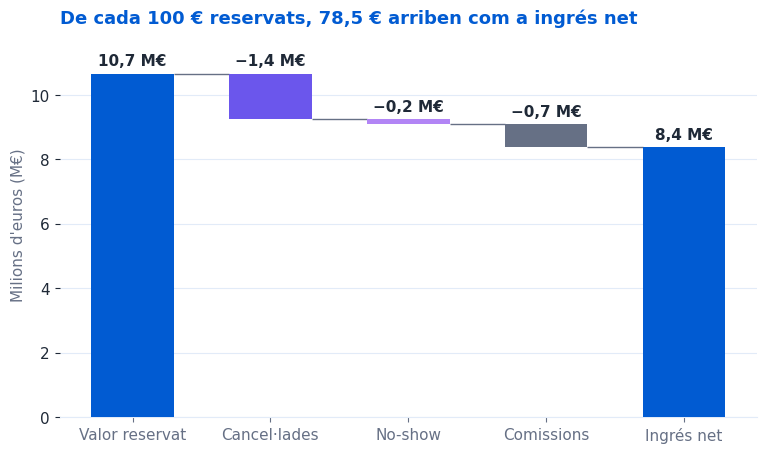

In [88]:
## Gràfic 1 · Cascada
vals = cascada / 1e6
totals = ["Valor reservat", "Ingrés net"]
col_barra = {"Valor reservat": COLORS["estat"]["Completada"],
             "Cancel·lades": COLORS["estat"]["Cancel·lada"],
             "No-show": COLORS["estat"]["No-show"],
             "Comissions": COLORS["text"]["caption"],
             "Ingrés net": COLORS["estat"]["Completada"]}

fig, ax = plt.subplots(figsize=(9, 5))
running = 0
for i, (nom, v) in enumerate(vals.items()):
    if nom in totals:
        bottom, h, running = 0, v, v
        etiqueta = f"{n1(v)} M€"
    else:
        bottom, h = running + v, -v
        running += v
        etiqueta = f"−{n1(-v)} M€"
    ax.bar(i, h, bottom=bottom, color=col_barra[nom], width=0.6, zorder=3)
    ax.text(i, bottom + h + 0.15, etiqueta, ha="center", va="bottom",
            fontweight="bold", color=COLORS["text"]["body"])
    if i < len(vals) - 1:
        ax.hlines(running, i + 0.3, i + 0.7, color=COLORS["text"]["caption"], lw=1, zorder=2)

ax.set_xticks(range(len(vals)))
ax.set_xticklabels(vals.index)
ax.set_ylabel("Milions d'euros (M€)")
ax.set_ylim(0, vals.iloc[0] * 1.12)
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
pct_net = vals["Ingrés net"] / vals["Valor reservat"] * 100
ax.set_title(f"De cada 100 € reservats, {n1(pct_net)} € arriben com a ingrés net")
desa(fig, "01_cascada_valor_reservado_ingreso_neto"); plt.show()

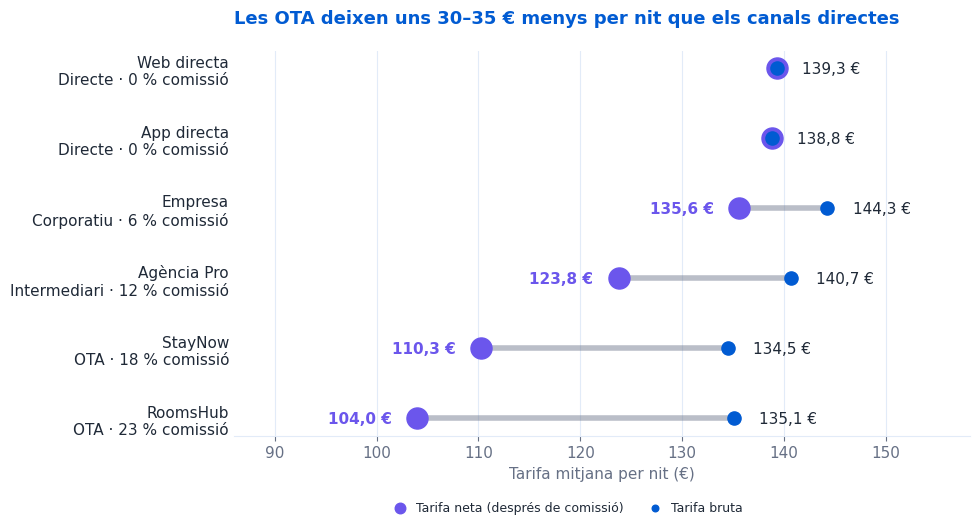

In [89]:
## Gràfic 2 · Tarifa bruta vs neta per canal
d = resum_canal.sort_values("tar_mitjana_net").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 5))
y = np.arange(len(d))

ax.hlines(y, d["tar_mitjana_net"], d["tar_mitjana_brut"],
          color=COLORS["text"]["caption"], alpha=0.45, lw=4, zorder=1)
# La neta (violeta, más grande) va debajo y la bruta (azul) encima:
# en los canales sin comisión se ve un punto concéntrico = bruta y neta coinciden
ax.scatter(d["tar_mitjana_net"], y, s=230, color=COLORS["highlight"]["focus"], zorder=3,
           label="Tarifa neta (després de comissió)")
ax.scatter(d["tar_mitjana_brut"], y, s=90, color=COLORS["series"][0], zorder=4, label="Tarifa bruta")

for i, r in d.iterrows():
    if r["tar_mitjana_brut"] - r["tar_mitjana_net"] < 0.5:     # canal sin comisión
        ax.text(r["tar_mitjana_brut"] + 2.5, i, f"{n1(r['tar_mitjana_brut'])} €", va="center")
    else:
        ax.text(r["tar_mitjana_net"] - 2.5, i, f"{n1(r['tar_mitjana_net'])} €", va="center", ha="right",
                color=COLORS["highlight"]["focus"], fontweight="bold")
        ax.text(r["tar_mitjana_brut"] + 2.5, i, f"{n1(r['tar_mitjana_brut'])} €", va="center")

ax.set_yticks(y)
ax.set_yticklabels([f"{r.nom_canal}\n{r.tipus_canal} · {r.comissio_pct:.0f} % comissió"
                    for r in d.itertuples()])
ax.set_xlim(d["tar_mitjana_net"].min() - 18, d["tar_mitjana_brut"].max() + 14)
ax.set_xlabel("Tarifa mitjana per nit (€)")
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=2, frameon=False,
          fontsize=9, markerscale=0.5, handletextpad=0.3, columnspacing=1.5)
ax.set_title("Les OTA deixen uns 30–35 € menys per nit que els canals directes", pad=20)
desa(fig, "02_tarifa_noche_bruta_neta_canal"); plt.show()

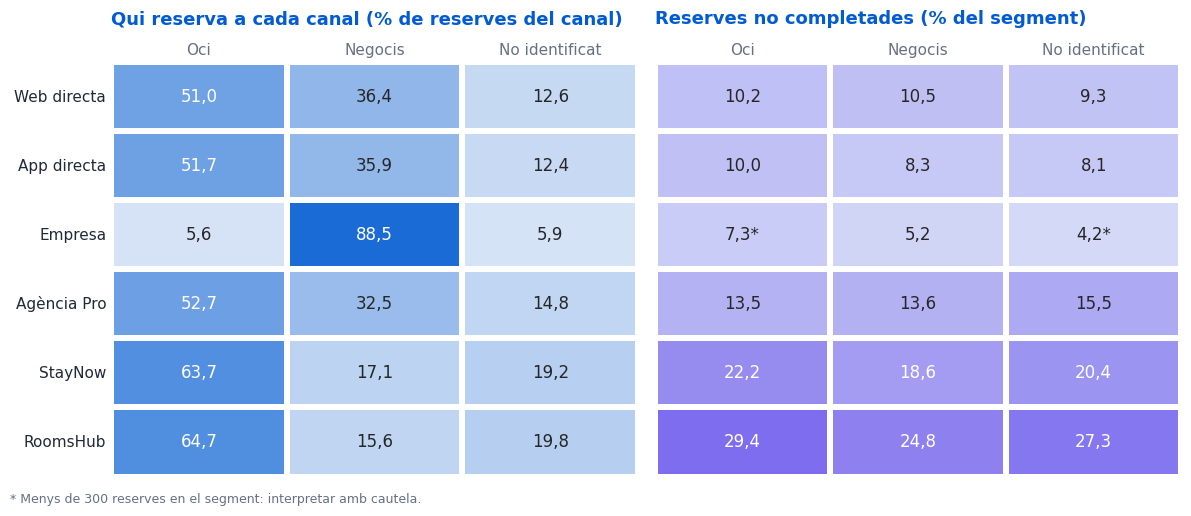

In [90]:
## Gràfic 3 · Heatmap canal × tipus de client
ordre_canals = ["Web directa", "App directa", "Empresa", "Agència Pro", "StayNow", "RoomsHub"]
ordre_client = ["Oci", "Negocis", "No identificat"]
MIN_N = 300   # por debajo, el % de no completadas es poco fiable

mix = mix_canal_client.loc[ordre_canals, ordre_client]
fall = fallides_canal_client.loc[ordre_canals, ordre_client]
n = n_canal_client.loc[ordre_canals, ordre_client]

def anotacio(df, marca_n=False):
    return df.apply(lambda col: [n1(v) + ("*" if marca_n and n.loc[idx_, col.name] < MIN_N else "")
                                 for idx_, v in col.items()])

cmap_blau = LinearSegmentedColormap.from_list("blau", [COLORS["sequential"]["low"], COLORS["sequential"]["high"]])
cmap_violeta = LinearSegmentedColormap.from_list("violeta", [COLORS["highlight"]["muted"], COLORS["highlight"]["focus"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.heatmap(mix, annot=anotacio(mix), fmt="", cmap=cmap_blau, vmin=0, vmax=100,
            linewidths=3, linecolor="white", cbar=False, ax=axes[0], annot_kws={"size": 12})
sns.heatmap(fall, annot=anotacio(fall, marca_n=True), fmt="", cmap=cmap_violeta, vmin=0, vmax=35,
            linewidths=3, linecolor="white", cbar=False, ax=axes[1], annot_kws={"size": 12})

axes[0].set_title("Qui reserva a cada canal (% de reserves del canal)", pad=28)
axes[1].set_title("Reserves no completades (% del segment)", pad=28)
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(length=0); ax.tick_params(axis="x", labelrotation=0)
    ax.xaxis.tick_top()
fig.text(0.01, -0.02, f"* Menys de {MIN_N} reserves en el segment: interpretar amb cautela.",
         color=COLORS["text"]["caption"], fontsize=9)
fig.tight_layout()
desa(fig, "03_mapa_calor_canal_tipo_cliente"); plt.show()

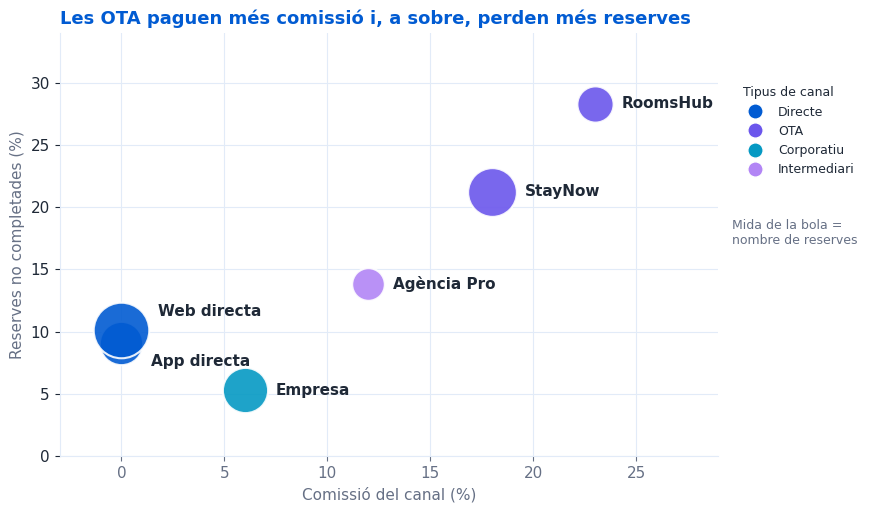

In [91]:
## Gràfic 4 · Comissió vs reserves no completades
fig, ax = plt.subplots(figsize=(8.5, 5.5))
max_res = resum_canal["reserves"].max()
dy_etiqueta = {"Web directa": 8, "App directa": -8}    # evita que se pisen las dos directas

for r in resum_canal.itertuples():
    s = r.reserves / max_res * 1600
    ax.scatter(r.comissio_pct, r.pct_no_completada, s=s, color=COLORS["tipus_canal"][r.tipus_canal],
               alpha=0.9, edgecolor="white", linewidth=1.5, zorder=3)
    dy = dy_etiqueta.get(r.nom_canal, 0)
    ax.annotate(r.nom_canal, (r.comissio_pct, r.pct_no_completada),
                xytext=(np.sqrt(s) / 2 + 6, dy), textcoords="offset points",
                va="bottom" if dy > 0 else "top" if dy < 0 else "center", fontweight="bold")

ax.set_xlim(-3, 29); ax.set_ylim(0, 34)
ax.set_xlabel("Comissió del canal (%)"); ax.set_ylabel("Reserves no completades (%)")
ax.grid(True); ax.set_axisbelow(True)
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=11, label=t)
           for t, c in COLORS["tipus_canal"].items()]
ax.legend(handles=handles, title="Tipus de canal", frameon=False, loc="upper left",
          bbox_to_anchor=(1.02, 0.9), fontsize=9, title_fontsize=9, alignment="left")
ax.text(1.02, 0.56, "Mida de la bola =\nnombre de reserves", transform=ax.transAxes,
        ha="left", va="top", color=COLORS["text"]["caption"], fontsize=9)
ax.set_title("Les OTA paguen més comissió i, a sobre, perden més reserves")
desa(fig, "04_burbujas_comision_reservas_no_completadas"); plt.show()

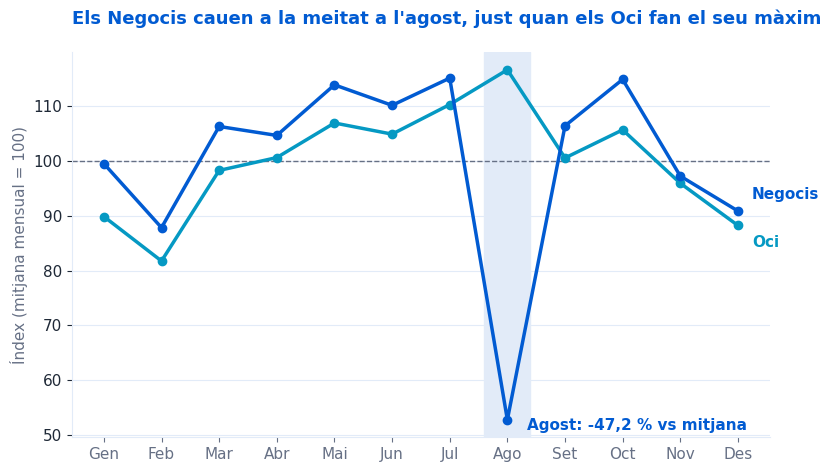

In [92]:
## Gràfic 5 · Estabilidad mensual: Negocio vs Ocio
mesos = ["Gen", "Feb", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Oct", "Nov", "Des"]
AGOST = 7   # posición del eje x (0 = gener)

fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(100, color=COLORS["text"]["caption"], lw=1, ls="--", zorder=1)

# Etiquetas directas al final de cada línea (sin leyenda)
ultims = index_100.iloc[-1].sort_values()
for k, (tipus, valor) in enumerate(ultims.items()):
    color = COLORS["tipus_client"][tipus]
    ax.plot(range(12), index_100[tipus], color=color, lw=2.5, marker="o", markersize=6, zorder=3)
    dy = (-12 if k == 0 else 12) if ultims.diff().iloc[-1] < 6 else 0
    ax.annotate(tipus, (11, valor), xytext=(10, dy), textcoords="offset points",
                va="center", color=color, fontweight="bold")

# Destacar agosto: el mes que explica la diferencia
ax.axvspan(AGOST - 0.4, AGOST + 0.4, color=COLORS["highlight"]["muted"], zorder=0)
caiguda = index_100["Negocis"].iloc[AGOST] - 100
ax.annotate(f"Agost: {n1(caiguda)} % vs mitjana", (AGOST, index_100["Negocis"].iloc[AGOST]),
            xytext=(14, -4), textcoords="offset points", va="center",
            color=COLORS["tipus_client"]["Negocis"], fontweight="bold")

ax.set_xticks(range(12)); ax.set_xticklabels(mesos)
ax.set_ylabel("Índex (mitjana mensual = 100)")
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title("Els Negocis cauen a la meitat a l'agost, just quan els Oci fan el seu màxim", pad=20)
desa(fig, "05_lineas_noches_mes_negocis_oci"); plt.show()

## 🕵️ Hallazgos y conclusiones

### 💡 Resultado general

- **Parte del valor reservado no llega a ser ingreso**. De cada 100 € reservados, 78,5 € llegan netos al hotel. Las cancelaciones y los no-show restan más del doble que las comisiones (Gráfico 1).

- **El cliente paga lo mismo, pero en las OTA al hotel le queda menos**. El precio por noche antes de comisión es parecido en todos los canales (entre 134 y 144 €). Tras pagar la comisión, al hotel le quedan unos 139 € por noche en los canales directos y entre 104 y 110 € en las OTA (Gráfico 2).

- **Las OTA, además, pierden más reservas**. Entre el 21 % y el 28 % de las reservas de StayNow y RoomsHub no se completan, frente al 9–10 % de Web y App y el 5 % de Empresa (Gráfico 4). Por eso, de media, una reserva recibida por RoomsHub deja 221 € netos y una de la App, 354 €.

- **Cada canal atrae a un tipo de cliente distinto, y pesa más el canal que el tipo de cliente**. Empresa es casi solo Negocis (88,5 %) y las OTA son sobre todo Oci (alrededor del 64 %). Dentro de un mismo canal, Oci y Negocis se comportan de forma parecida (como mucho unos 5 puntos de diferencia en reservas no completadas), mientras que entre canales la diferencia supera los 20 puntos (Gráfico 3). Además, un 14 % de las reservas son de clientes sin identificar, y se concentran más en las OTA (cerca del 20 %) que en Web y App (12–13 %).

- **Los Negocis son estables casi todo el año, salvo en agosto**. En agosto sus noches caen casi a la mitad, justo cuando los Oci tienen su mejor mes (Gráfico 5). Sin agosto, los dos perfiles varían un 9 %.

### 🚀 Propuestas

- **Reducir el peso de las OTA y hacer sus reservas más fiables**

Se recomiendo pedir un depósito o usar tarifas no reembolsables en las OTA. Asi como, dar una pequeña ventaja a los clientes Oci que reserven directamente en la web o la app, y pedirles que se registren al reservar.

Las OTA son el canal con más comisión (18–23 %), con menos ingreso neto por noche (30–35 € menos que en directo, Gráfico 2) y con más reservas perdidas (Gráfico 4). En cambio, los Oci son quienes más reservan por OTA (Gráfico 3), así que son el grupo al que dirigir el incentivo.


- **Llenar el hueco de agosto con clientes de empresa**

Una campaña dirigida a las empresas clientes (canal Empresa) con tarifas o paquetes pensados para agosto.

En agosto los Negocis registran 903 noches, frente a una media de unas 1.780 el resto de meses, es decir, unas 880 noches menos de lo habitual (Gráfico 5). Empresa es el canal más fiable, con solo un 5 % de reservas no completadas (Gráfico 4). Su tarifa neta (unos 136 € por noche) es casi igual a la de los canales directos (139 €, Gráfico 2).

### 🚫 Limitaciones

- **Datos de un solo año (2025)**. No sabemos si el patrón de agosto se repetiría, y los resultados describen lo que pasa, no por qué pasa. Además, las noches se cuentan en el mes de entrada, aunque la estancia continúe el mes siguiente.
- **Entendemos “rentabilidad” como ingreso tras comisión, no beneficio**. No hay datos de costes, penalizaciones ni otros ingresos. El valor de las reservas canceladas es solo valor potencial, porque no sabemos si la habitación se volvió a vender.
- **No sabemos qué clientes llegarían sin las OTA**. Estas también dan visibilidad y pueden traer clientes nuevos, así que reducir su peso podría tener un coste que estos datos no miden. Además, el 14 % de reservas sin identificar impide conocer a esos clientes.
- **N sabemos qué pasa en agosto**: Los datos no explican por qué cae agosto. Puede ser el parón vacacional, pero es una hipótesis. Por eso la propuesta debería ser una prueba de comparación entre el año de resgitro y el nuevo año.